# Lagged spatial maps and the event-vector test (items 9 and 13)

Loads and plots only. The numbers come from two scripts, run per region:

    python run_lagged_spatial_maps.py --region lec|pfc   # item 9 + 13a (gated on his cell 34)
    python anchor_distribution.py --region lec|pfc       # item 13b

Write-up: `code/LAGGED_SPATIAL.md`. Maps are El-Gaby's saved `Phase_shifted_maps`
(Figure5_Figure6 cell 76); no refit.

In [1]:
RUN_MODE = 'load'   # this notebook never computes; rerun the scripts above instead
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lagged_spatial_maps as lsm
import anchor_distribution as ad

REGIONS = ('lec', 'pfc')
LSM, AD = {}, {}
for r in REGIONS:
    with open(os.path.join(lsm.OUT_DIRS[r], 'lagged_spatial_maps.pkl'), 'rb') as fh:
        LSM[r] = pickle.load(fh)
    with open(os.path.join(lsm.OUT_DIRS[r], 'anchor_distribution.pkl'), 'rb') as fh:
        AD[r] = pickle.load(fh)
FIG = {r: lsm.OUT_DIRS[r] for r in REGIONS}

## Equivalence gate: rebuilt cell 31 against his printed cell 34

In [2]:
rows = []
for r in REGIONS:
    for p in ('all', 'nonzero', 'strict'):
        (n0, t0), (n1, t1) = LSM[r]['cell34'][p], LSM[r]['gate'][p]
        rows.append({'region': r, 'panel': p, 'his n': n0, 'our n': n1, 'his t': t0, 'our t': t1,
                     'dt': t1 - t0})
pd.DataFrame(rows)

,region,panel,his n,our n,his t,our t,dt
0,lec,all,1426,1426,45.509781,45.509781,0.0
1,lec,nonzero,356,356,8.421138,8.421138,0.0
2,lec,strict,179,179,5.825788,5.825788,0.0
3,pfc,all,738,738,20.208118,20.208118,0.0
4,pfc,nonzero,307,307,5.722014,5.722014,0.0
5,pfc,strict,164,164,3.815675,3.815675,0.0


## Item 9: held-out lagged-map correlation (Fig. 5f / ED 7h), per neuron and per mouse

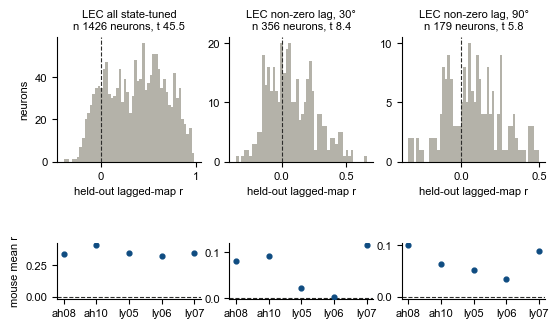

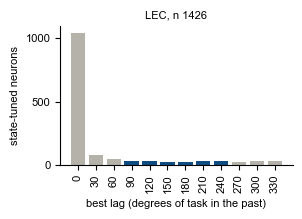

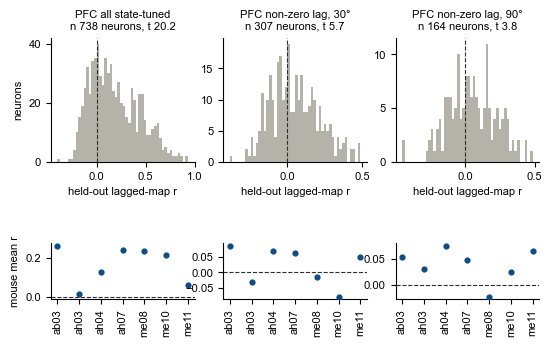

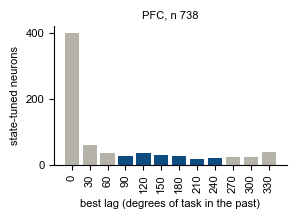

In [3]:
for r in REGIONS:
    lsm.plot_heldout_population(LSM[r]['table'], r,
                                out_path=os.path.join(FIG[r], 'heldout_population.svg'))
    lsm.plot_best_lag(LSM[r]['table'], r, out_path=os.path.join(FIG[r], 'best_lag.svg'))
plt.show()

## Example lagged maps (Fig. 5e layout, nodes only)

Rows are tasks, columns are lags with the current location on the right, each 3x3 node map
normalised on its own (as in the paper). Goal letters a-d are drawn at the best lag, which is
also zoomed on the right with its max rate. The bar row is the cross-task correlation of the node
maps at each lag. Examples: the top three held-out r in the 90° set, one per recday, among units
firing 0.5-20 Hz with >= 5 tasks, plus the best lag-0 neuron for contrast. Choosing on r alone
picked a 48 Hz and a 0.3 Hz unit.

,recday,neuron,kind,rate_hz,r_all,r_strict,best_lag_modal,group
2773,ly07_20250624_20250625,8,lagged 90°,13.223618,0.412503,0.497239,3.0,ENTm
201,ah08_20250616_20250617,50,lagged 90°,0.564239,0.458627,0.458627,8.0,ENTl-sup
643,ah08_20250624_20250625,37,lagged 90°,1.581131,0.335290,0.449425,3.0,ENTl-sup
371,ah08_20250618_20250619,56,lag 0,0.677366,0.983233,NaN,0.0,ENTl-sup


,recday,neuron,kind,rate_hz,r_all,r_strict,best_lag_modal
229,ah04_01122021_02122021,1,lagged 90°,0.736940,0.422184,0.485576,6.0
45,ab03_01092023_02092023,45,lagged 90°,0.770895,0.440539,0.440539,8.0
823,ah07_27082023_28082023,17,lagged 90°,0.569447,0.360128,0.431620,3.0
29,ab03_01092023_02092023,29,lag 0,11.266420,0.933443,NaN,0.0


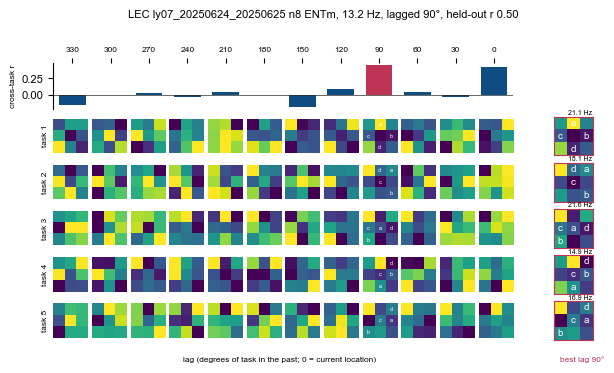

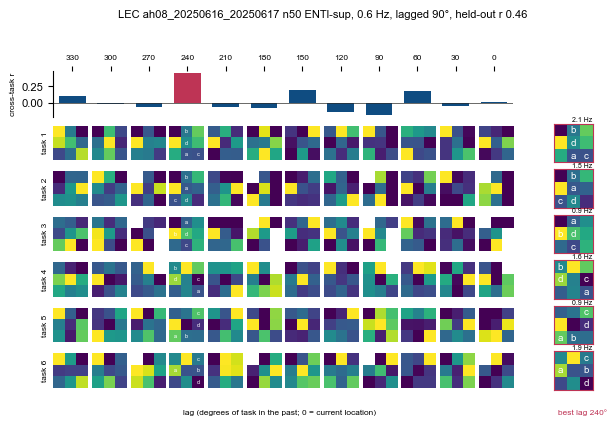

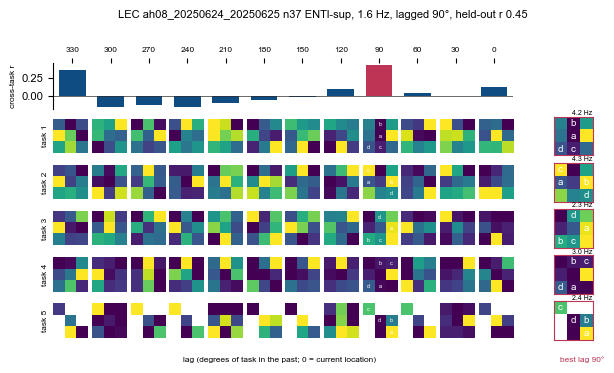

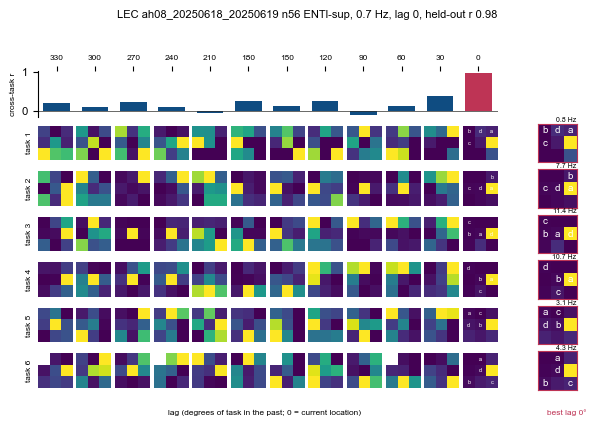

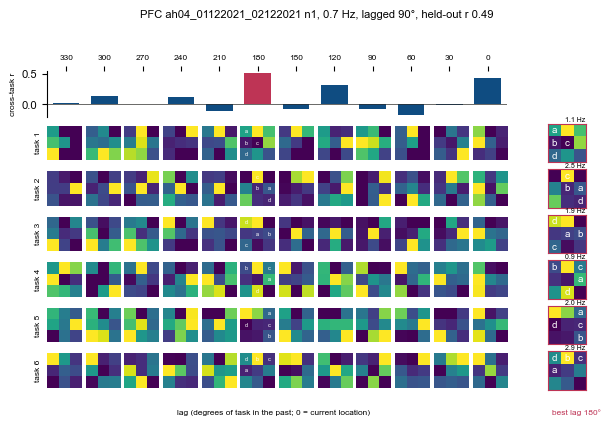

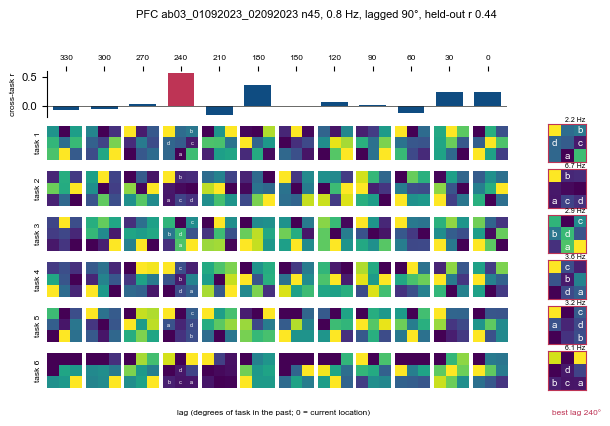

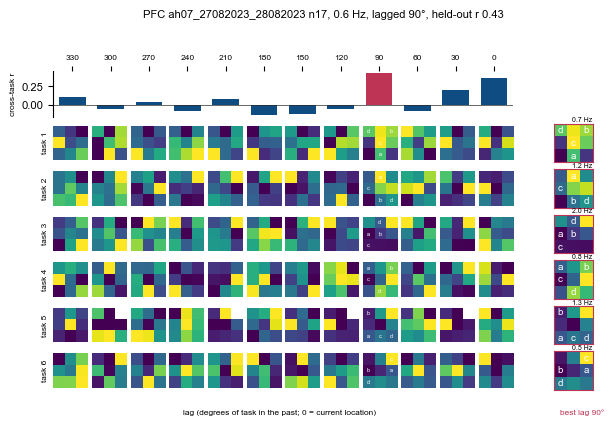

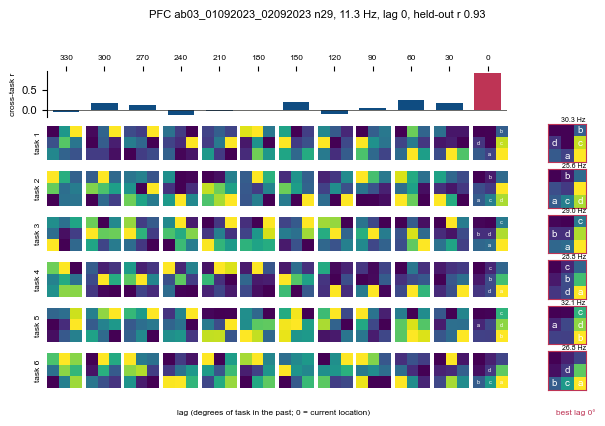

In [4]:
for r in REGIONS:
    ex = lsm.pick_examples(LSM[r]['table'])
    display(ex[['recday', 'neuron', 'kind', 'rate_hz', 'r_all', 'r_strict', 'best_lag_modal']
               + (['group'] if 'group' in ex else [])])
    for _, row in ex.iterrows():
        rec = lsm.load_recday(r, row.recday, rates=False)
        g = f" {row.group}" if isinstance(row.get('group'), str) else ''
        r_show = row.r_strict if row.kind != 'lag 0' else row.r_all
        lsm.plot_lagged_maps(rec, int(row.neuron),
                             title=f"{r.upper()} {row.recday} n{int(row.neuron)}{g}, "
                                   f"{row.rate_hz:.1f} Hz, {row.kind}, held-out r {r_show:.2f}",
                             out_path=os.path.join(FIG[r], f"maps_{row.recday}_n{int(row.neuron)}.svg"))
plt.show()

## Item 13a: place frame vs goal frame

Both frames correlate 4-vectors from the same maps at the held-out best lag: the place frame reads
session *t* at session *s*'s goal nodes, the goal frame at *t*'s own goal nodes (same letter A-D).
A pure state-tuned cell is goal-frame consistent by construction.

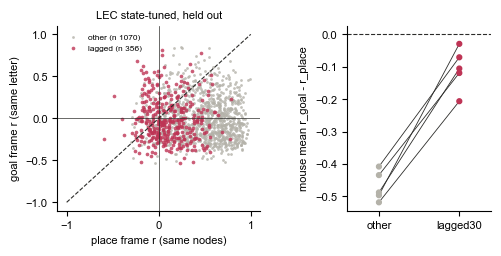

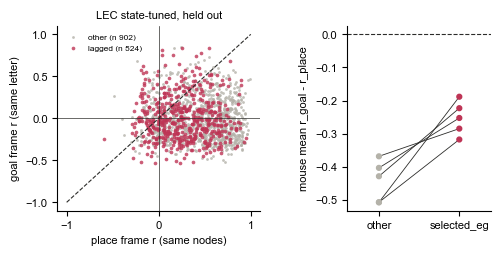

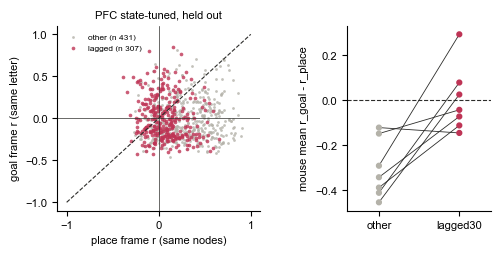

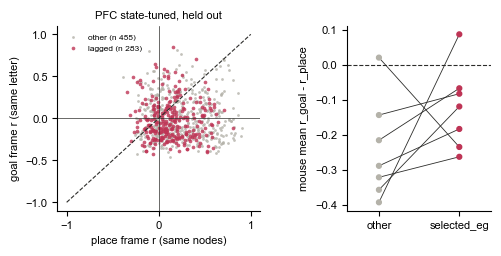

In [5]:
for r in REGIONS:
    for col in ('lagged30', 'selected_eg'):
        lsm.plot_frame_test(LSM[r]['table'], r, lag_col=col,
                            out_path=os.path.join(FIG[r], f'frame_test_{col}.svg'))
plt.show()

## LEC anatomy (per mouse; mice are the replicates)

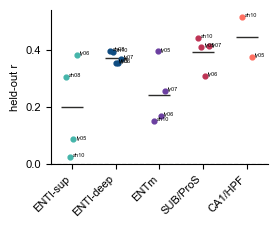

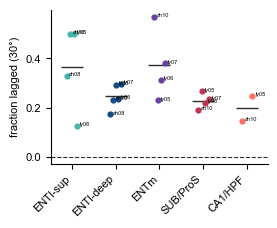

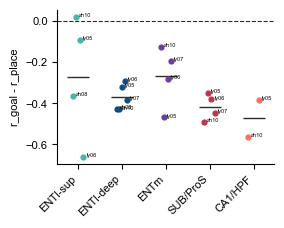

In [6]:
t = LSM['lec']['table'].assign(f30=lambda d: d.lagged30.astype(float),
                                  delta=lambda d: d.r_goal - d.r_place)
for col, lab in (('r_all', 'held-out r'), ('f30', 'fraction lagged (30°)'),
                 ('delta', 'r_goal - r_place')):
    lsm.plot_anatomy(t, col, lab, out_path=os.path.join(FIG['lec'], f'anatomy_{col}.svg'))
plt.show()

## Item 13b: are anchors at reward ports? (visit-weighted null)

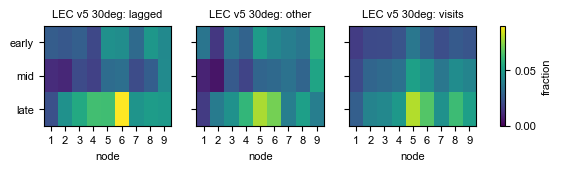

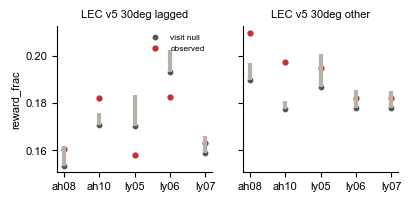

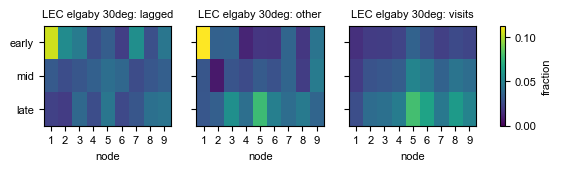

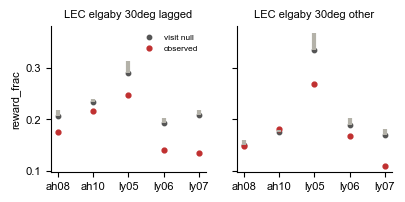

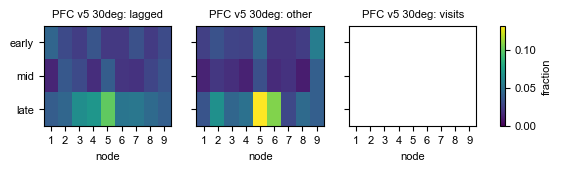

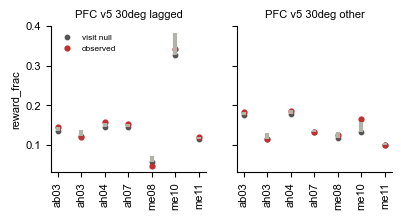

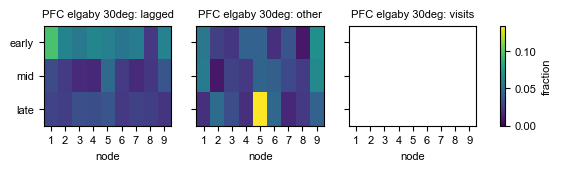

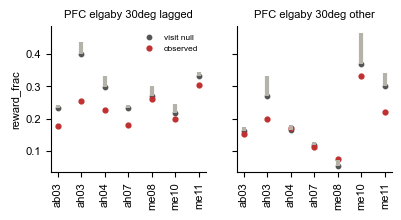

In [7]:
for r in REGIONS:
    for src in ('v5', 'elgaby'):
        ad.plot_anchor_histograms(AD[r], src, '30deg',
                                  out_path=os.path.join(FIG[r], f'anchor_hist_{src}.svg'))
        ad.plot_occupancy_null(AD[r], src, '30deg', 'reward_frac',
                               out_path=os.path.join(FIG[r], f'anchor_null_{src}.svg'))
plt.show()

## Printed summaries

In [8]:
for r in REGIONS:
    for f in ('lagged_spatial_maps_summary.txt', 'anchor_distribution_summary.txt'):
        print(open(os.path.join(lsm.OUT_DIRS[r], f)).read())

== equivalence gate, LEC: rebuilt cell 31 vs his cell-34 print
  all      his n  1426 t 45.5097814915 | ours n  1426 t 45.5097814915 | dt +0.0e+00 OK
  nonzero  his n   356 t 8.4211380118 | ours n   356 t 8.4211380118 | dt +0.0e+00 OK
  strict   his n   179 t 5.8257878239 | ours n   179 t 5.8257878239 | dt +0.0e+00 OK
== LEC: 2851 units, 1426 state-tuned, 25 recdays, 5 mice
-- Fig. 5f held-out lagged-map r, state-tuned, per mouse (recday mean -> mouse mean)
  mouse      n   r_all    r_30  n_30    r_90  n_90   f_30   f_90
  ah08     290   0.337   0.082    81   0.100    46  0.276  0.155
  ah10     544   0.409   0.093   122   0.064    59  0.222  0.108
  ly05     149   0.352   0.023    34   0.052    19  0.294  0.163
  ly06     201   0.325   0.004    42   0.035    23  0.225  0.124
  ly07     242   0.346   0.115    77   0.089    32  0.309  0.130
  mice with mean r > 0, all: 5/5, one-sided binomial p 0.0312
  mice with mean r > 0, 30 deg: 5/5, one-sided binomial p 0.0312
  mice with mean r > 